# YOLOv8m face expression classifier (6 classes) – emp_edu dataset, 70 / 15 / 15 split

One of four comparable notebooks in `D:\Shitol\last_codes` (**YOLOv8m, YOLO11s, YOLO11m, YOLO11l**). All four use
**the same data, the same split (same seed), the same face crops and the same training settings** – only the model differs,
so their results can be compared directly.

* **Model:** `yolov8m-cls.pt` – the ImageNet-pretrained **classification** version of YOLOv8m
  (detection model in the Ultralytics table: 25.9M / 78.9B / 50.2% params / FLOPs / COCO mAP).
* **Data:** `D:\Research\Dataset\Multi-culture\emp_edu\<class>\` (angry, fear, happy, neutral, sad, surprise).
* **Split:** stratified per class – **70 % train / 15 % validation (eval) / 15 % test**. Byte-identical duplicate files are
  kept together in one split; duplicates filed under two different classes are removed (ambiguous label).
* **Pipeline:** YuNet face detection → square face crop → YOLOv8m-cls fine-tuned at 256 px.
* **Outputs:** `last_codes/outputs/yolov8m/` – weights, training curves, metrics with **per-class accuracy**, confusion
  matrices, predictions, misclassified examples and an **ONNX model** for the web app. The last cell compares all
  models that have finished so far.

## 0. Environment

In [21]:
# Installs only what is missing (PyTorch should already be the CUDA build).
import sys, subprocess, importlib, importlib.util
NEEDED = {"ultralytics": "ultralytics", "sklearn": "scikit-learn", "pandas": "pandas", "matplotlib": "matplotlib",
          "seaborn": "seaborn", "cv2": "opencv-python", "PIL": "pillow", "onnx": "onnx", "onnxruntime": "onnxruntime"}
missing = [pkg for mod, pkg in NEEDED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing, "--disable-pip-version-check"])
    importlib.invalidate_caches()
import torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available())

torch 2.11.0+cu128 | CUDA: True


In [22]:
import os, json, time, shutil, random, hashlib, threading, urllib.request
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import ultralytics
from ultralytics import YOLO

sns.set_theme(style="whitegrid")
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} | {p.total_memory / 1024**3:.1f} GB")
else:
    print("WARNING: no CUDA GPU - training will be slow.")
print("Ultralytics", ultralytics.__version__, "| opencv", cv2.__version__)

GPU: NVIDIA GeForce RTX 5070 Ti | 15.9 GB
Ultralytics 8.4.165 | opencv 5.0.0


## 1. Configuration

In [23]:
# ---------------- Model ----------------
MODEL_WEIGHTS = "yolov8m-cls.pt"          # ImageNet-pretrained classification weights
MODEL_NAME = "yolov8m"

# ---------------- Paths ----------------
PROJECT_ROOT = Path(os.environ.get("FER_PROJECT_ROOT", r"D:\Shitol"))
DATA_DIR = Path(os.environ.get("FER_SOURCE_DIR", r"D:\Research\Dataset\Multi-culture\emp_edu"))   # <class>/<image>
CODE_DIR = PROJECT_ROOT / "last_codes"                                                # the four notebooks
BASE_OUT = Path(os.environ.get("FER_OUT_DIR", CODE_DIR / "outputs"))
WORK_DIR = BASE_OUT / "_shared_work"         # face crops + split folders, SHARED by all four notebooks (same split)
OUT_DIR = BASE_OUT / MODEL_NAME              # this model's runs, plots, metrics, ONNX
DETECTOR_PATH = PROJECT_ROOT / "weights" / "face_detection_yunet_2023mar.onnx"       # downloaded if missing
WEIGHT_DIRS = [CODE_DIR, PROJECT_ROOT, PROJECT_ROOT / "new_code", PROJECT_ROOT / "yolo11l",
               PROJECT_ROOT / "best_model_yolo11m_augmented"]

CLASS_NAMES = ["angry", "fear", "happy", "neutral", "sad", "surprise"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ---------------- Split 70 / 15 / 15 (identical in all four notebooks) ----------------
SEED = 42
TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION = 0.70, 0.15, 0.15

# ---------------- Face crops ----------------
USE_FACE_CROP = True            # crop the largest face with YuNet (same as the web app); False = whole images
FACE_MARGIN = 0.20
CROP_SIZE = 320
ASSUME_CROP_BELOW = 100         # images smaller than this are already face crops

# ---------------- Training (identical in all four notebooks) ----------------
IMG_SIZE = 256
EPOCHS = 60
PATIENCE = 15
BATCH = 32
WORKERS = min(8, os.cpu_count() or 2)
CACHE = "ram"
DEVICE = 0 if torch.cuda.is_available() else "cpu"
TRAIN_ARGS = dict(
    optimizer="AdamW", lr0=3e-4, lrf=0.01, cos_lr=True, warmup_epochs=3, weight_decay=0.05,
    dropout=0.3,
    scale=0.30,                 # random crops keep 70-100 % of the face crop
    fliplr=0.5, flipud=0.0,
    hsv_h=0.015, hsv_s=0.5, hsv_v=0.4,
    auto_augment="randaugment",
    erasing=0.10,
)
EXPORT_ONNX = True

SMOKE_TEST = os.environ.get("FER_SMOKE_TEST", "") == "1"     # tiny run, only for checking the code
SMOKE_PER_CLASS = 20
if SMOKE_TEST:
    MODEL_WEIGHTS, IMG_SIZE, EPOCHS, PATIENCE, BATCH, WORKERS, CACHE = "yolo11n-cls.yaml", 64, 1, 1, 16, 0, False

assert abs(TRAIN_FRACTION + VAL_FRACTION + TEST_FRACTION - 1) < 1e-9
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
for d in (WORK_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)
missing_classes = [c for c in CLASS_NAMES if not (DATA_DIR / c).is_dir()]
if missing_classes:
    raise FileNotFoundError(f"class folders missing in {DATA_DIR}: {missing_classes}")
print("Model:", MODEL_WEIGHTS, "| data:", DATA_DIR, "| outputs:", OUT_DIR, "| device:", DEVICE, "| smoke test:", SMOKE_TEST)

Model: yolov8m-cls.pt | data: D:\Research\Dataset\Multi-culture\emp_edu | outputs: D:\Shitol\last_codes\outputs\yolov8m | device: 0 | smoke test: False


## 2. Helper functions (image reading, face detection and cropping)

In [24]:
def list_images(folder):
    return sorted(p for p in Path(folder).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)

def file_md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

def read_bgr(path):
    # works with non-ASCII paths on Windows
    try:
        data = np.fromfile(str(path), dtype=np.uint8)
        return cv2.imdecode(data, cv2.IMREAD_COLOR) if data.size else None
    except Exception:
        return None

def center_square(img):
    h, w = img.shape[:2]; s = min(h, w)
    return img[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]

def square_crop(img, box, margin=FACE_MARGIN):
    # square crop around box (x, y, w, h) + margin on every side; borders padded by edge replication
    x, y, bw, bh = [float(v) for v in box[:4]]
    cx, cy = x + bw / 2, y + bh / 2
    side = max(bw, bh) * (1 + 2 * margin)
    x1, y1, x2, y2 = [int(round(v)) for v in (cx - side / 2, cy - side / 2, cx + side / 2, cy + side / 2)]
    h, w = img.shape[:2]
    crop = img[max(0, y1):min(h, y2), max(0, x1):min(w, x2)]
    pads = (max(0, -y1), max(0, y2 - h), max(0, -x1), max(0, x2 - w))
    if crop.size and any(pads):
        crop = cv2.copyMakeBorder(crop, *pads, cv2.BORDER_REPLICATE)
    return crop, (max(0, x1), max(0, y1), min(w, x2), min(h, y2))

class FaceCropper:
    # YuNet face detector; large photos are detected on a downscaled copy, small ones on an upscaled copy
    def __init__(self, model_path, margin=FACE_MARGIN, score_threshold=0.6, max_side=1280, min_side=320):
        self.margin, self.max_side, self.min_side = margin, max_side, min_side
        self.det = cv2.FaceDetectorYN.create(str(model_path), "", (320, 320), score_threshold, 0.3, 50)

    def detect(self, img):
        h, w = img.shape[:2]
        s = self.max_side / max(h, w) if max(h, w) > self.max_side else (
            self.min_side / min(h, w) if min(h, w) < self.min_side else 1.0)
        im = img if s == 1.0 else cv2.resize(img, (max(1, round(w * s)), max(1, round(h * s))),
                                             interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR)
        self.det.setInputSize((im.shape[1], im.shape[0]))
        _, faces = self.det.detect(im)
        if faces is None or len(faces) == 0:
            return np.zeros((0, 5), np.float32)
        boxes = np.concatenate([faces[:, :4] / s, faces[:, 14:15]], 1)
        return boxes[np.argsort(-(boxes[:, 2] * boxes[:, 3]))]       # largest face first

    def largest_face(self, img):
        boxes = self.detect(img)
        if len(boxes):
            crop, _ = square_crop(img, boxes[0], self.margin)
            if crop.size:
                return crop, True
        return center_square(img), False

def resolve_weights(name):
    for d in WEIGHT_DIRS:
        if (d / name).exists():
            return str(d / name)
    return name                                   # Ultralytics downloads it otherwise

if USE_FACE_CROP and not DETECTOR_PATH.exists():
    DETECTOR_PATH.parent.mkdir(parents=True, exist_ok=True)
    url = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
    print("Downloading YuNet:", url)
    urllib.request.urlretrieve(url, DETECTOR_PATH)
print("Face detector:", DETECTOR_PATH if USE_FACE_CROP else "not used", "| weights:", resolve_weights(MODEL_WEIGHTS))

Face detector: D:\Shitol\weights\face_detection_yunet_2023mar.onnx | weights: D:\Shitol\yolov8m-cls.pt


In [25]:
# Permanently convert source images in DATA_DIR to grayscale before indexing.
from PIL import ImageOps


def grayscale_source_image(path):
    with Image.open(path) as image:
        if image.mode in ("L", "LA"):
            return False

        image_format = {".jpg": "JPEG", ".jpeg": "JPEG", ".png": "PNG"}.get(path.suffix.lower())
        if image_format is None:
            raise ValueError(f"unsupported image format for {path}")

        has_alpha = "A" in image.getbands() or "transparency" in image.info
        grayscale = ImageOps.grayscale(image.convert("RGB"))
        if has_alpha:
            alpha = image.convert("RGBA").getchannel("A")
            grayscale.putalpha(alpha)

        save_options = {}
        if image_format == "JPEG":
            save_options["quality"] = 95
        for key in ("exif", "icc_profile"):
            if key in image.info:
                save_options[key] = image.info[key]

        temp_path = path.with_name(path.name + ".grayscale.tmp")
        try:
            grayscale.save(temp_path, format=image_format, **save_options)
            temp_path.replace(path)
        finally:
            temp_path.unlink(missing_ok=True)
        return True


source_images = [p for c in CLASS_NAMES for p in list_images(DATA_DIR / c)]
converted = 0
for index, image_path in enumerate(source_images, start=1):
    converted += grayscale_source_image(image_path)
    if index % 1000 == 0:
        print(f"Processed {index}/{len(source_images)} source images")
print(f"Grayscale conversion complete: {converted} converted; {len(source_images) - converted} already grayscale.")

Processed 1000/21555 source images
Processed 2000/21555 source images
Processed 3000/21555 source images
Processed 4000/21555 source images
Processed 5000/21555 source images
Processed 6000/21555 source images
Processed 7000/21555 source images
Processed 8000/21555 source images
Processed 9000/21555 source images
Processed 10000/21555 source images
Processed 11000/21555 source images
Processed 12000/21555 source images
Processed 13000/21555 source images
Processed 14000/21555 source images
Processed 15000/21555 source images
Processed 16000/21555 source images
Processed 17000/21555 source images
Processed 18000/21555 source images
Processed 19000/21555 source images
Processed 20000/21555 source images
Processed 21000/21555 source images
Grayscale conversion complete: 0 converted; 21555 already grayscale.


## 3. Index the dataset

Every file in `emp_edu/<class>/` is one sample. Files with identical bytes (md5) form one group, so a duplicate can never
sit in both train and test. A group whose copies are filed under **different** classes has an ambiguous label and is removed.

In [26]:
records = [{"path": str(p), "label": c, "name": p.name} for c in CLASS_NAMES for p in list_images(DATA_DIR / c)]
df = pd.DataFrame(records)
if SMOKE_TEST:
    df = df.groupby("label").head(SMOKE_PER_CLASS).reset_index(drop=True)
with ThreadPoolExecutor(8) as pool:
    df["group"] = list(pool.map(file_md5, df["path"]))

labels_per_group = df.groupby("group")["label"].nunique()
conflicts = set(labels_per_group[labels_per_group > 1].index)
n_files = len(df)
df = df[~df["group"].isin(conflicts)].reset_index(drop=True)

counts = pd.DataFrame({"files": df.groupby("label").size(),
                       "unique images": df.groupby("label")["group"].nunique()}).reindex(CLASS_NAMES)
counts["share"] = (counts["unique images"] / counts["unique images"].sum()).map("{:.1%}".format)
display(counts)
print(f"Files: {n_files} | exact duplicates (kept together): {len(df) - df['group'].nunique()} | "
      f"removed (same image in >1 class): {n_files - len(df)} files in {len(conflicts)} groups")

,files,unique images,share
label,,,
angry,3304,3301,15.3%
fear,2167,2167,10.1%
happy,4879,4879,22.7%
neutral,4154,4154,19.3%
sad,3949,3949,18.3%
surprise,3088,3088,14.3%


Files: 21555 | exact duplicates (kept together): 3 | removed (same image in >1 class): 14 files in 7 groups


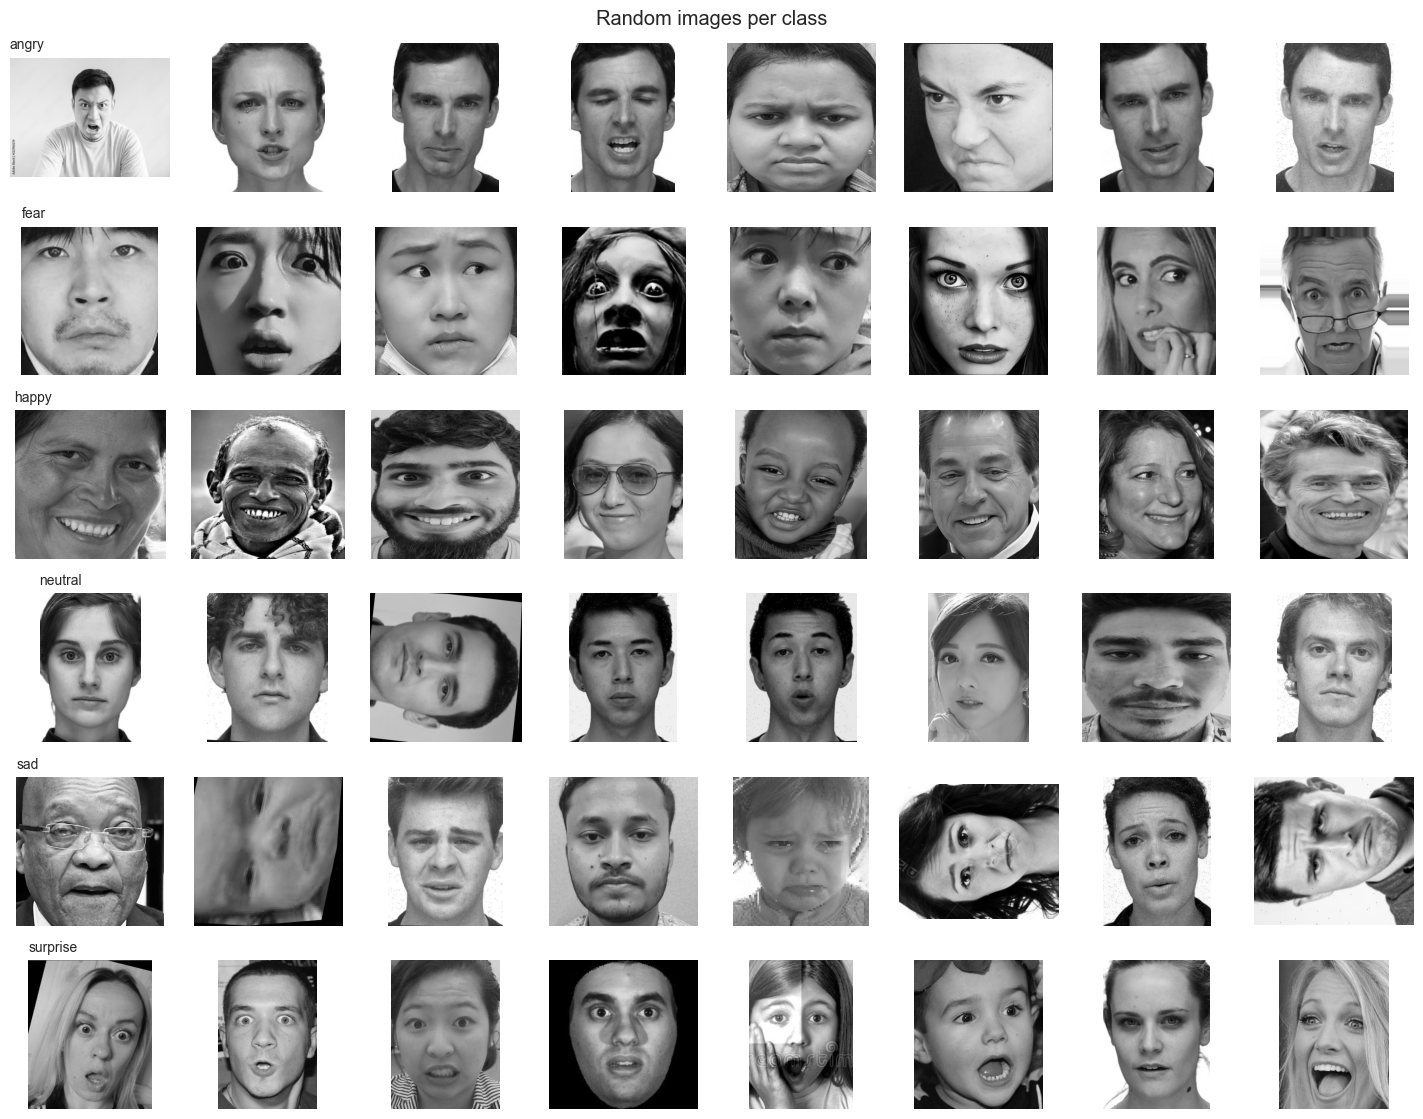

In [27]:
cols = 8
fig, axes = plt.subplots(len(CLASS_NAMES), cols, figsize=(1.8 * cols, 1.9 * len(CLASS_NAMES)))
for r, c in enumerate(CLASS_NAMES):
    sub = df[df["label"] == c].sample(min(cols, (df["label"] == c).sum()), random_state=SEED)
    for k in range(cols):
        ax = axes[r, k]; ax.axis("off")
        if k < len(sub):
            img = read_bgr(sub.iloc[k]["path"])
            if img is not None:
                ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            if k == 0: ax.set_title(c, loc="left", fontsize=10)
plt.suptitle("Random images per class"); plt.tight_layout(); plt.show()

## 4. Split 70 / 15 / 15 (train / validation = eval / test)

Stratified by class and made on the duplicate groups. Same seed in all four notebooks, so **every model sees exactly
the same train, validation and test images**. Saved to `outputs/<model>/split.csv`.

In [28]:
groups = df.drop_duplicates("group")[["group", "label"]]
train_g, rest_g = train_test_split(groups, test_size=VAL_FRACTION + TEST_FRACTION,
                                   stratify=groups["label"], random_state=SEED)
val_g, test_g = train_test_split(rest_g, test_size=TEST_FRACTION / (VAL_FRACTION + TEST_FRACTION),
                                 stratify=rest_g["label"], random_state=SEED)
split_of = {**dict.fromkeys(train_g["group"], "train"), **dict.fromkeys(val_g["group"], "val"),
            **dict.fromkeys(test_g["group"], "test")}
df["split"] = df["group"].map(split_of)
assert df["split"].notna().all()
df.to_csv(OUT_DIR / "split.csv", index=False)

SPLITS = ["train", "val", "test"]
tab = pd.crosstab(df["label"], df["split"]).reindex(index=CLASS_NAMES, columns=SPLITS)
tab.loc["total"] = tab.sum()
tab["total"] = tab.sum(axis=1)
display(tab)
print({s: f"{(df['split'] == s).mean():.1%}" for s in SPLITS})

split,train,val,test,total
label,,,,
angry,2313,496,495,3304
fear,1517,325,325,2167
happy,3415,732,732,4879
neutral,2908,623,623,4154
sad,2764,592,593,3949
surprise,2161,464,463,3088
total,15078,3232,3231,21541


{'train': '70.0%', 'val': '15.0%', 'test': '15.0%'}


## 5. Face crops and the Ultralytics folder dataset

The largest face in every image is cropped with YuNet and written to `outputs/_shared_work/dataset/<split>/<class>/`.
This folder is **shared by all four notebooks**: the first notebook that runs creates it (a few minutes), the others
reuse it. Source-image content changes invalidate the crop cache. If no face is found, the centre square is used; those files are listed in `no_face_detected.csv`.
Run the notebooks **one after another**, not at the same time.

In [29]:
DATASET_DIR = WORK_DIR / "dataset"
sig = hashlib.md5(("|".join(df["path"] + ":" + df["split"] + ":" + df["group"]) + f"|{USE_FACE_CROP}|{FACE_MARGIN}|{CROP_SIZE}").encode()).hexdigest()[:12]
sig_file = DATASET_DIR / "signature.txt"
if DATASET_DIR.exists() and (not sig_file.exists() or sig_file.read_text() != sig):
    shutil.rmtree(DATASET_DIR)                    # split / settings changed -> rebuild
df["crop_path"] = [str(DATASET_DIR / s / l / f"{i:05d}_{Path(p).stem}.jpg")
                   for i, (p, l, s) in enumerate(zip(df["path"], df["label"], df["split"]))]
for s in SPLITS:
    for c in CLASS_NAMES:                         # Ultralytics needs every class folder, even if empty
        (DATASET_DIR / s / c).mkdir(parents=True, exist_ok=True)

_tls = threading.local()
def crop_one(row):
    img = read_bgr(row.path)
    if img is None:
        return "unreadable"
    if not USE_FACE_CROP:
        crop, mode = img, "whole_image"
    elif min(img.shape[:2]) < ASSUME_CROP_BELOW:
        crop, mode = center_square(img), "already_crop"
    else:
        if getattr(_tls, "cropper", None) is None:
            _tls.cropper = FaceCropper(DETECTOR_PATH, FACE_MARGIN)   # one detector per thread
        crop, found = _tls.cropper.largest_face(img)
        mode = "detected" if found else "no_face"
    if max(crop.shape[:2]) > CROP_SIZE:
        f = CROP_SIZE / max(crop.shape[:2])
        crop = cv2.resize(crop, (round(crop.shape[1] * f), round(crop.shape[0] * f)), interpolation=cv2.INTER_AREA)
    cv2.imencode(".jpg", crop, [cv2.IMWRITE_JPEG_QUALITY, 95])[1].tofile(row.crop_path)
    return mode

index_file = DATASET_DIR / "crop_index.csv"
done = pd.read_csv(index_file).set_index("crop_path")["crop_mode"].to_dict() if index_file.exists() else {}
todo = [r for r in df.itertuples() if r.crop_path not in done or not Path(r.crop_path).exists()]
t0 = time.perf_counter()
with ThreadPoolExecutor(os.cpu_count() or 4) as pool:
    for r, mode in zip(todo, pool.map(crop_one, todo)):
        done[r.crop_path] = mode
pd.Series(done, name="crop_mode").rename_axis("crop_path").reset_index().to_csv(index_file, index=False)
sig_file.write_text(sig)
print(f"Prepared {len(todo)} new images in {time.perf_counter() - t0:.0f}s (0 = reused the shared crops)")

df["crop_mode"] = df["crop_path"].map(done)
bad = df["crop_mode"] == "unreadable"
if bad.any():
    print(f"Skipping {bad.sum()} unreadable files:", df.loc[bad, "path"].tolist()[:10])
    for p in df.loc[bad, "crop_path"]:
        Path(p).unlink(missing_ok=True)
df = df[~bad].reset_index(drop=True)
display(pd.crosstab(df["split"], df["crop_mode"]).reindex(SPLITS))
df.loc[df["crop_mode"] == "no_face", ["path", "label", "split"]].to_csv(OUT_DIR / "no_face_detected.csv", index=False)

Prepared 21541 new images in 68s (0 = reused the shared crops)


crop_mode,already_crop,detected,no_face
split,,,
train,21,13886,1171
val,4,2999,229
test,5,2969,257


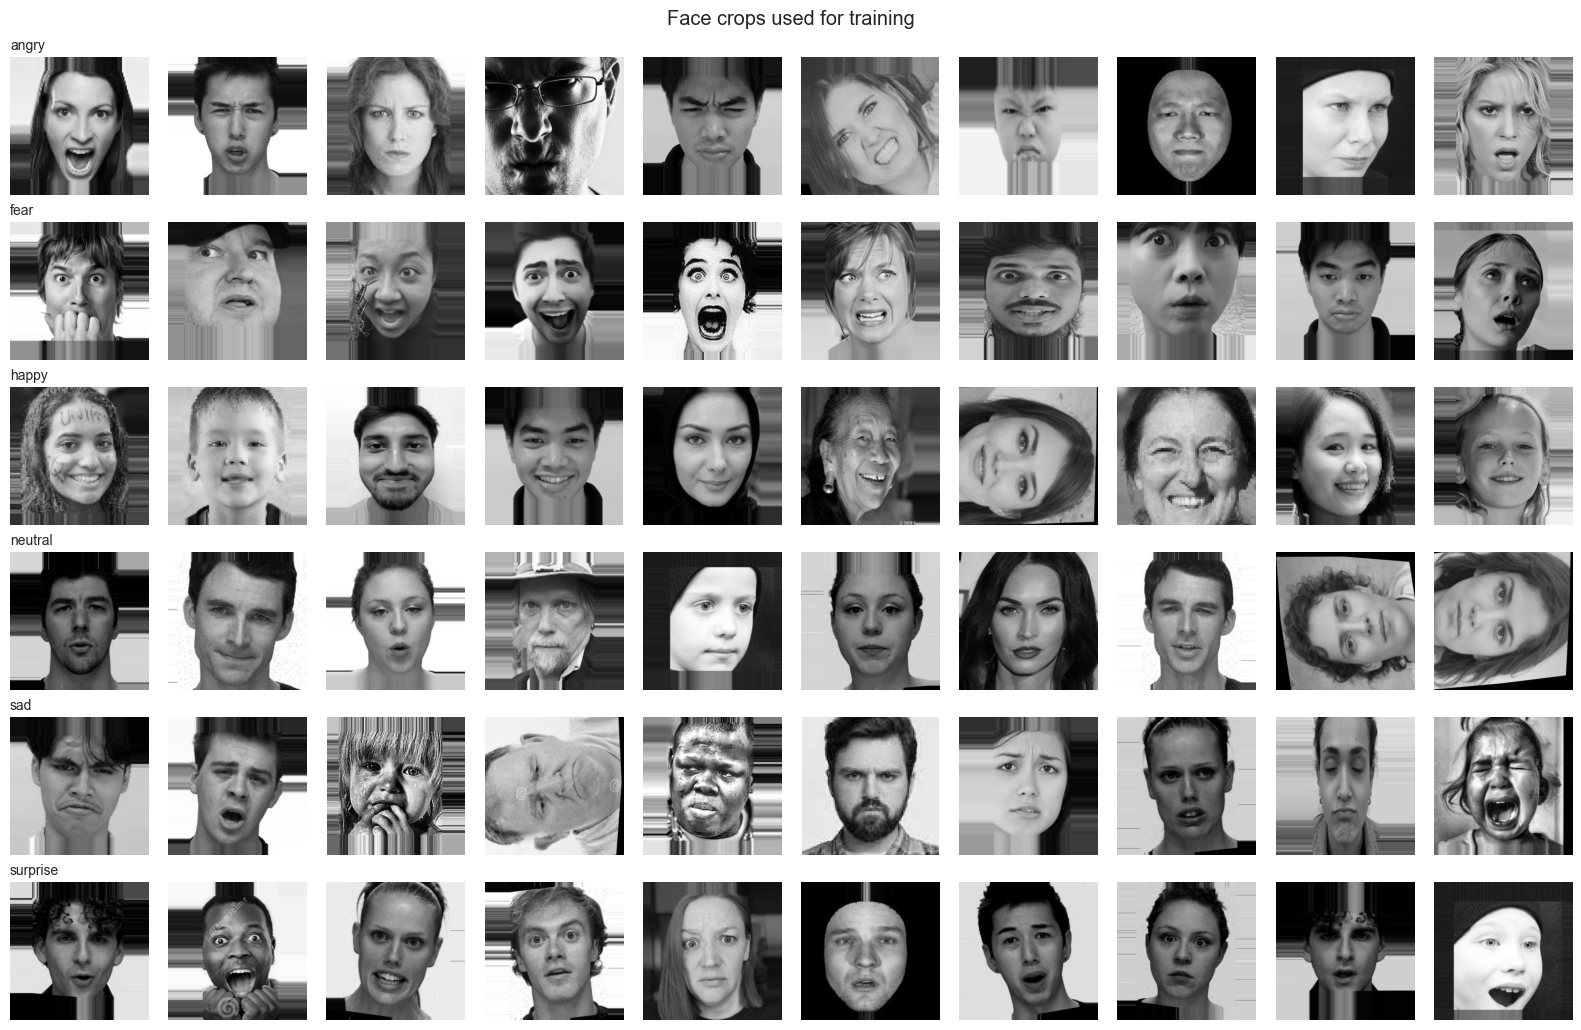

In [30]:
cols = 10
fig, axes = plt.subplots(len(CLASS_NAMES), cols, figsize=(1.6 * cols, 1.75 * len(CLASS_NAMES)))
for r, c in enumerate(CLASS_NAMES):
    sub = df[(df["label"] == c) & (df["split"] == "train")]
    sub = sub.sample(min(cols, len(sub)), random_state=SEED)
    for k in range(cols):
        ax = axes[r, k]; ax.axis("off")
        if k < len(sub):
            ax.imshow(Image.open(sub.iloc[k]["crop_path"]).convert("RGB"))
            if k == 0: ax.set_title(c, loc="left", fontsize=10)
plt.suptitle("Face crops used for training"); plt.tight_layout()
plt.savefig(OUT_DIR / "crop_preview.png", dpi=120); plt.show()

## 6. Train YOLOv8m-cls

Ultralytics trains on `dataset/train` and selects the best epoch on `dataset/val`. The test split is **not** used during
training. If `best.pt` already exists for the current split, training is skipped, so the notebook can be re-run for
evaluation only.

In [31]:
RUN_NAME = f"{MODEL_NAME}_70_15_15"
run = OUT_DIR / "runs" / RUN_NAME
best_pt = run / "weights" / "best.pt"
if best_pt.exists() and (run / "split_sig.txt").exists() and (run / "split_sig.txt").read_text() == sig:
    print("Already trained for this split - skipped:", best_pt)
    train_minutes = json.load(open(OUT_DIR / "metrics.json")).get("train_minutes") if (OUT_DIR / "metrics.json").exists() else None
else:
    if run.exists():
        shutil.rmtree(run)
    t0 = time.perf_counter()
    model = YOLO(resolve_weights(MODEL_WEIGHTS))
    model.train(data=str(DATASET_DIR), epochs=EPOCHS, patience=PATIENCE, imgsz=IMG_SIZE, batch=BATCH,
                device=DEVICE, workers=WORKERS, cache=CACHE, amp=True, seed=SEED, deterministic=False,
                project=str(OUT_DIR / "runs"), name=RUN_NAME, exist_ok=True, pretrained=True, plots=True, verbose=False,
                **TRAIN_ARGS)
    best_pt = Path(model.trainer.best)
    (run / "split_sig.txt").write_text(sig)
    train_minutes = (time.perf_counter() - t0) / 60
    print(f"Training finished in {train_minutes:.1f} min | best weights: {best_pt}")
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

New https://pypi.org/project/ultralytics/8.4.201 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.165  Python-3.14.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=D:\Shitol\last_codes\outputs\_shared_work\dataset, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.3, dynamic=False, embed=None, epochs=60, erasing=0.1, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=256, iou=0.7, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mod

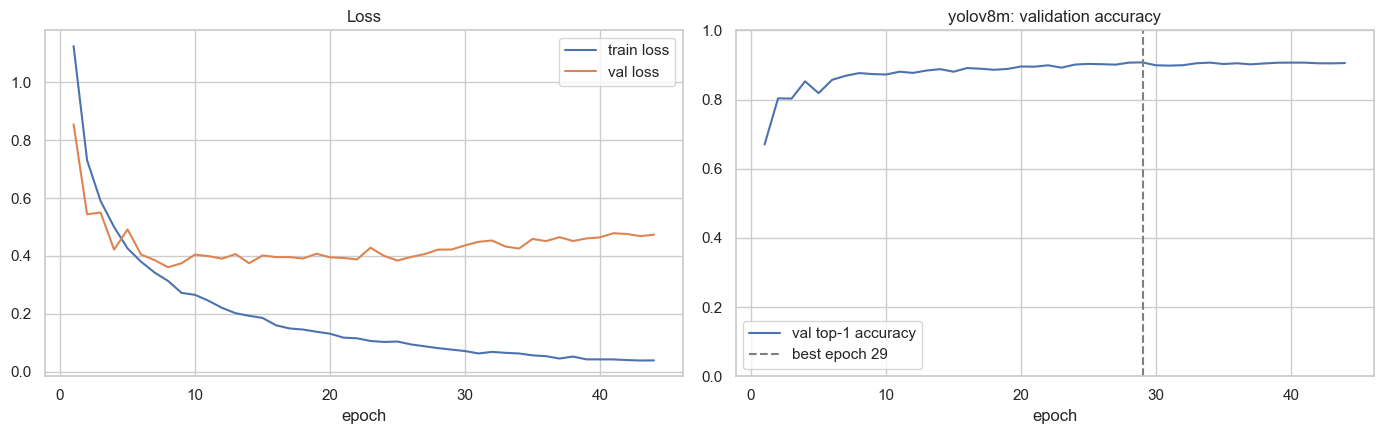

Best epoch 29 | val top-1 0.9075 | epochs run 44


In [32]:
hist = pd.read_csv(run / "results.csv")
hist.columns = [c.strip() for c in hist.columns]
best_row = hist.loc[hist["metrics/accuracy_top1"].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(hist["epoch"], hist["train/loss"], label="train loss")
if "val/loss" in hist:
    axes[0].plot(hist["epoch"], hist["val/loss"], label="val loss")
axes[0].set(title="Loss", xlabel="epoch"); axes[0].legend()
axes[1].plot(hist["epoch"], hist["metrics/accuracy_top1"], label="val top-1 accuracy")
axes[1].axvline(best_row["epoch"], color="gray", ls="--", label=f"best epoch {int(best_row['epoch'])}")
axes[1].set(title=f"{MODEL_NAME}: validation accuracy", xlabel="epoch", ylim=(0, 1)); axes[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=150); plt.show()
print(f"Best epoch {int(best_row['epoch'])} | val top-1 {best_row['metrics/accuracy_top1']:.4f} | epochs run {len(hist)}")

## 7. Prediction helper

Predicts on the face crops in batches and returns probabilities in `CLASS_NAMES` order. Optional flip TTA averages each
face with its mirror image. Whether TTA is used is decided on the **validation** split, never on test.

In [33]:
model = YOLO(str(best_pt))
ORDER = [{n: i for i, n in model.names.items()}[c] for c in CLASS_NAMES]

def predict_probs(model, paths, tta=False, batch=64):
    out = []
    for i in range(0, len(paths), batch):
        imgs = [read_bgr(p) for p in paths[i:i + batch]]
        res = model.predict(imgs, imgsz=IMG_SIZE, device=DEVICE, verbose=False)
        p = np.stack([r.probs.data.float().cpu().numpy() for r in res])
        if tta:
            res = model.predict([np.ascontiguousarray(im[:, ::-1]) for im in imgs], imgsz=IMG_SIZE, device=DEVICE, verbose=False)
            p = (p + np.stack([r.probs.data.float().cpu().numpy() for r in res])) / 2
        out.append(p[:, ORDER])
    return np.concatenate(out)

CID = {c: i for i, c in enumerate(CLASS_NAMES)}
paths = {s: df.loc[df["split"] == s, "crop_path"].tolist() for s in SPLITS}
y_true = {s: df.loc[df["split"] == s, "label"].map(CID).to_numpy() for s in SPLITS}

val_plain = predict_probs(model, paths["val"], tta=False)
val_tta = predict_probs(model, paths["val"], tta=True)
acc_plain, acc_tta = accuracy_score(y_true["val"], val_plain.argmax(1)), accuracy_score(y_true["val"], val_tta.argmax(1))
USE_TTA = acc_tta > acc_plain
print(f"Validation accuracy: plain {acc_plain:.4f} | flip TTA {acc_tta:.4f} -> USE_TTA = {USE_TTA}")

probs = {"val": val_tta if USE_TTA else val_plain}
t0 = time.perf_counter()
probs["test"] = predict_probs(model, paths["test"], tta=USE_TTA)
ms_per_image = (time.perf_counter() - t0) / max(1, len(paths["test"])) * 1000
probs["train"] = predict_probs(model, paths["train"], tta=USE_TTA)
y_pred = {s: probs[s].argmax(1) for s in SPLITS}
print(f"Inference speed on test: {ms_per_image:.1f} ms/image (PyTorch, batch 64, {'with' if USE_TTA else 'no'} TTA)")

Validation accuracy: plain 0.9075 | flip TTA 0.9109 -> USE_TTA = True
Inference speed on test: 5.7 ms/image (PyTorch, batch 64, with TTA)


## 8. Results: overall and per-class accuracy

In [34]:
summary = pd.DataFrame({s: {"images": len(y_true[s]),
                            "accuracy": accuracy_score(y_true[s], y_pred[s]),
                            "macro F1": f1_score(y_true[s], y_pred[s], average="macro")} for s in SPLITS}).T
display(summary.style.format({"images": "{:.0f}", "accuracy": "{:.2%}", "macro F1": "{:.4f}"}))

idx = np.random.default_rng(0).integers(0, len(y_true["test"]), (2000, len(y_true["test"])))
ci = np.quantile((y_true["test"][idx] == y_pred["test"][idx]).mean(1), [0.025, 0.975])
print(f"{MODEL_NAME} TEST accuracy {summary.loc['test', 'accuracy']:.4f} (95% CI {ci[0]:.3f}-{ci[1]:.3f}) | "
      f"macro-F1 {summary.loc['test', 'macro F1']:.4f} | TTA: {USE_TTA}")

# per-class accuracy (= recall of each class) for every split
per_class = pd.DataFrame({f"{s} acc": pd.Series(y_pred[s] == y_true[s]).groupby(
                              pd.Series(y_true[s]).map(dict(enumerate(CLASS_NAMES)))).mean() for s in SPLITS})
per_class["test correct / total"] = [f"{((y_pred['test'] == y_true['test']) & (y_true['test'] == i)).sum()} / "
                                     f"{(y_true['test'] == i).sum()}" for i in range(len(CLASS_NAMES))]
per_class = per_class.reindex(CLASS_NAMES)
print("\nPer-class accuracy:")
display(per_class.style.format({f"{s} acc": "{:.2%}" for s in SPLITS}))

,images,accuracy,macro F1
train,15078,99.78%,0.9976
val,3232,91.09%,0.9062
test,3231,90.56%,0.9013


yolov8m TEST accuracy 0.9056 (95% CI 0.895-0.916) | macro-F1 0.9013 | TTA: True

Per-class accuracy:


,train acc,val acc,test acc,test correct / total
angry,99.78%,86.69%,88.69%,439 / 495
fear,99.67%,87.38%,87.38%,284 / 325
happy,99.97%,97.81%,95.63%,700 / 732
neutral,99.76%,90.85%,89.89%,560 / 623
sad,99.78%,89.36%,89.04%,528 / 593
surprise,99.58%,90.30%,89.63%,415 / 463


In [35]:
for s in ("val", "test"):
    print(f"=============== {MODEL_NAME} {s.upper()} ===============")
    print(classification_report(y_true[s], y_pred[s], labels=range(len(CLASS_NAMES)), target_names=CLASS_NAMES,
                                digits=4, zero_division=0))

=============== yolov8m VAL ===============
              precision    recall  f1-score   support

       angry     0.9368    0.8669    0.9005       496
        fear     0.8738    0.8738    0.8738       325
       happy     0.9275    0.9781    0.9521       732
     neutral     0.8789    0.9085    0.8934       623
         sad     0.9152    0.8936    0.9043       592
    surprise     0.9229    0.9030    0.9129       464

    accuracy                         0.9109      3232
   macro avg     0.9092    0.9040    0.9062      3232
weighted avg     0.9112    0.9109    0.9106      3232

=============== yolov8m TEST ===============
              precision    recall  f1-score   support

       angry     0.9281    0.8869    0.9070       495
        fear     0.8503    0.8738    0.8619       325
       happy     0.9321    0.9563    0.9440       732
     neutral     0.8777    0.8989    0.8882       623
         sad     0.8964    0.8904    0.8934       593
    surprise     0.9305    0.8963    0.9131

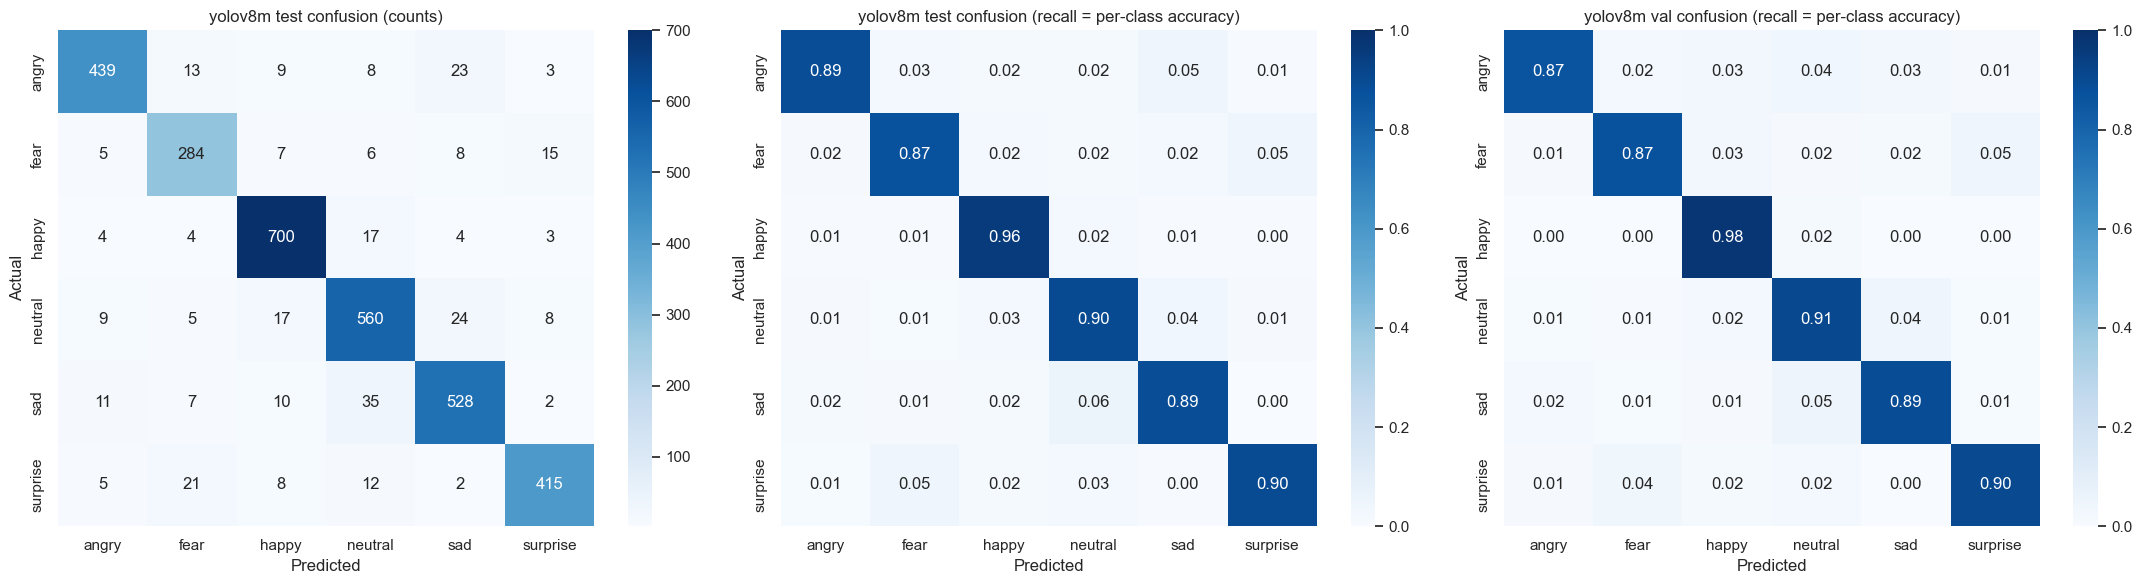

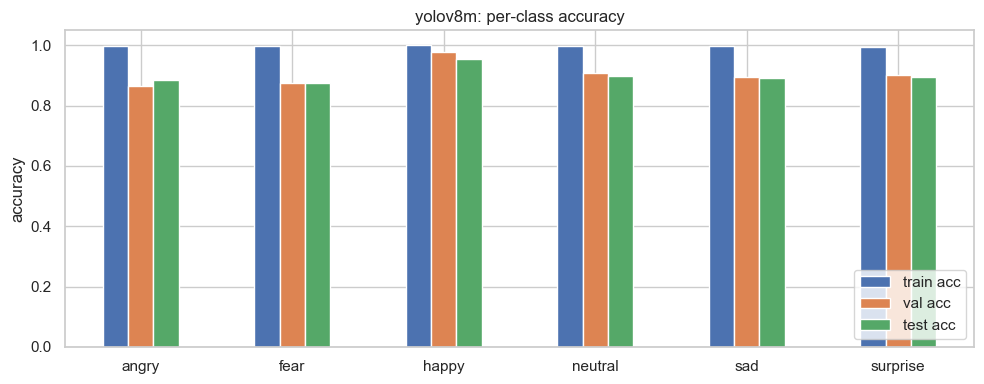

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for ax, s, norm in ((axes[0], "test", False), (axes[1], "test", True), (axes[2], "val", True)):
    cm = confusion_matrix(y_true[s], y_pred[s], labels=range(len(CLASS_NAMES)))
    if norm:
        sns.heatmap(cm / cm.sum(1, keepdims=True).clip(1), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    else:
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set(title=f"{MODEL_NAME} {s} confusion ({'recall = per-class accuracy' if norm else 'counts'})",
           xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrices.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
per_class[[f"{s} acc" for s in SPLITS]].plot.bar(ax=ax, rot=0, ylim=(0, 1.05))
ax.set(title=f"{MODEL_NAME}: per-class accuracy", ylabel="accuracy"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT_DIR / "per_class_accuracy.png", dpi=150); plt.show()

In [37]:
pred_df = df[["path", "crop_path", "label", "split", "crop_mode"]].copy()
for s in SPLITS:
    m = (pred_df["split"] == s).to_numpy()
    pred_df.loc[m, "predicted"] = [CLASS_NAMES[i] for i in y_pred[s]]
    pred_df.loc[m, "confidence"] = probs[s].max(1)
    for j, c in enumerate(CLASS_NAMES):
        pred_df.loc[m, f"p_{c}"] = probs[s][:, j]
pred_df["correct"] = pred_df["label"] == pred_df["predicted"]
pred_df.to_csv(OUT_DIR / "predictions_all_splits.csv", index=False)

metrics = {
    "model": MODEL_NAME, "weights": MODEL_WEIGHTS, "img_size": IMG_SIZE, "tta": bool(USE_TTA), "seed": SEED,
    "split_fractions": {"train": TRAIN_FRACTION, "val": VAL_FRACTION, "test": TEST_FRACTION},
    "images": {s: int(len(y_true[s])) for s in SPLITS},
    "accuracy": {s: round(float(summary.loc[s, "accuracy"]), 4) for s in SPLITS},
    "macro_f1": {s: round(float(summary.loc[s, "macro F1"]), 4) for s in SPLITS},
    "test_ci95": [float(ci[0]), float(ci[1])],
    "per_class_accuracy": {s: per_class[f"{s} acc"].round(4).to_dict() for s in SPLITS},
    "best_epoch": int(best_row["epoch"]), "epochs_run": int(len(hist)),
    "train_minutes": None if train_minutes is None else round(train_minutes, 1),
    "inference_ms_per_image": round(ms_per_image, 2),
    "parameters_millions": round(sum(p.numel() for p in model.model.parameters()) / 1e6, 2),
    "weights_mb": round(best_pt.stat().st_size / 1e6, 1),
}
json.dump(metrics, open(OUT_DIR / "metrics.json", "w"), indent=2)
print("Saved predictions_all_splits.csv and metrics.json in", OUT_DIR)

Saved predictions_all_splits.csv and metrics.json in D:\Shitol\last_codes\outputs\yolov8m


## 9. Misclassified test images

305 of 3231 test images are misclassified (most confident first)


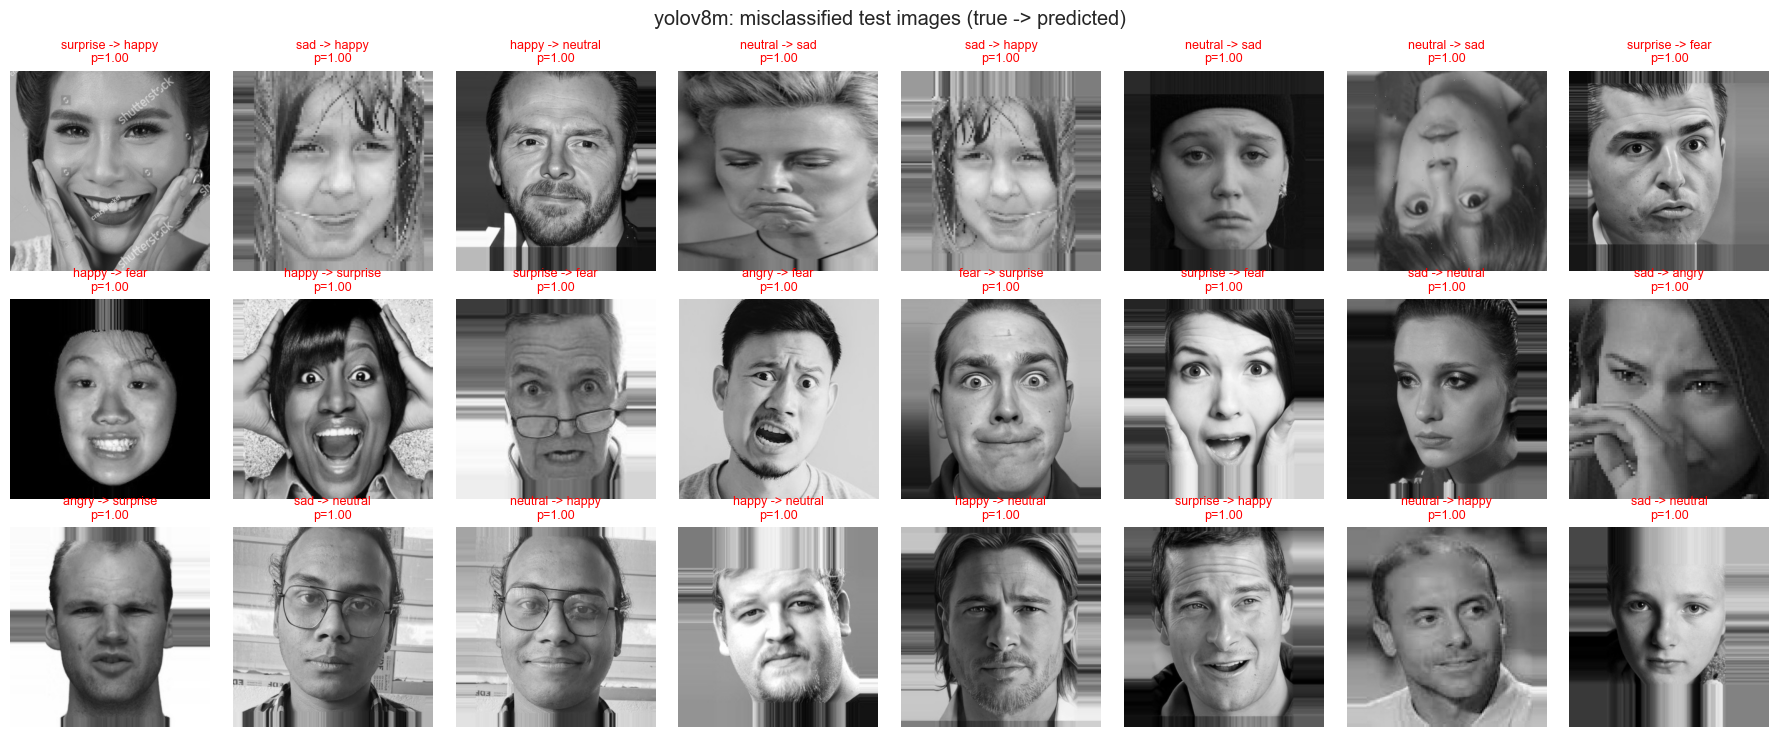

In [38]:
wrong = pred_df[(pred_df["split"] == "test") & ~pred_df["correct"]].sort_values("confidence", ascending=False)
n = min(24, len(wrong))
print(f"{len(wrong)} of {(pred_df['split'] == 'test').sum()} test images are misclassified (most confident first)")
if n:
    fig, axes = plt.subplots(3, 8, figsize=(18, 7.5))
    for ax, (_, r) in zip(axes.ravel(), wrong.head(n).iterrows()):
        ax.imshow(Image.open(r["crop_path"]).convert("RGB")); ax.axis("off")
        ax.set_title(f"{r['label']} -> {r['predicted']}\np={r['confidence']:.2f}", fontsize=9, color="red")
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    plt.suptitle(f"{MODEL_NAME}: misclassified test images (true -> predicted)"); plt.tight_layout(); plt.show()

## 10. Export to ONNX (for the web application)

Input `float32 N×3×256×256` RGB in [0, 1] (YuNet face crop, short side resized to 256, centre-cropped); output
**probabilities in `CLASS_NAMES` order**, flip TTA inside the graph if chosen. Same interface as the model in
`face_expression_webapp`: copy the `.onnx` into the web app's `model/` folder as `yolo_face_expression_ensemble.onnx`
together with `deployment_metadata.json`.

In [39]:
class ExportWrapper(nn.Module):
    def __init__(self, net, order, tta):
        super().__init__()
        self.net, self.tta = net, bool(tta)
        self.register_buffer("order", torch.tensor(order), persistent=False)
    def forward(self, x):
        p = self.net(x)[:, self.order]
        if self.tta:
            p = (p + self.net(torch.flip(x, dims=[3]))[:, self.order]) / 2
        return p

def onnx_prep(img, s=IMG_SIZE):
    h, w = img.shape[:2]; f = s / min(h, w)
    img = cv2.resize(img, (max(s, round(w * f)), max(s, round(h * f))), interpolation=cv2.INTER_LINEAR)
    y0, x0 = (img.shape[0] - s) // 2, (img.shape[1] - s) // 2
    return cv2.cvtColor(img[y0:y0 + s, x0:x0 + s], cv2.COLOR_BGR2RGB).transpose(2, 0, 1).astype(np.float32) / 255

ONNX_PATH = OUT_DIR / f"{MODEL_NAME}_face_expression.onnx"
if EXPORT_ONNX:
    import onnx, onnxruntime as ort
    net = YOLO(str(best_pt)).model.float().cpu().eval()
    net.model[-1].export = True                          # Classify head returns probabilities only
    wrapper = ExportWrapper(net, ORDER, USE_TTA).eval()
    dummy = torch.rand(2, 3, IMG_SIZE, IMG_SIZE)
    torch.onnx.export(wrapper, (dummy,), str(ONNX_PATH), input_names=["images"], output_names=["probs"],
                      opset_version=17, dynamic_axes={"images": {0: "batch"}, "probs": {0: "batch"}}, dynamo=False)
    onnx.checker.check_model(onnx.load(str(ONNX_PATH)))
    sess = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])
    with torch.no_grad():
        diff = float(np.abs(wrapper(dummy).numpy() - sess.run(None, {"images": dummy.numpy()})[0]).max())
    onnx_probs = np.concatenate([sess.run(None, {"images": np.stack([onnx_prep(read_bgr(p)) for p in paths["test"][i:i + 32]])})[0]
                                 for i in range(0, len(paths["test"]), 32)])
    onnx_acc = accuracy_score(y_true["test"], onnx_probs.argmax(1))
    meta = {"classes": CLASS_NAMES, "image_size": IMG_SIZE, "output": "probabilities",
            "input": "float32 [N,3,S,S] RGB 0-1; YuNet face crop, short side -> S, centre crop",
            "face_detector": DETECTOR_PATH.name, "face_margin": FACE_MARGIN, "tta_inside_model": bool(USE_TTA),
            "grayscale_inside_model": False, "model": MODEL_NAME, "test_acc": float(summary.loc["test", "accuracy"]),
            "onnx_test_acc": float(onnx_acc), "dataset": str(DATA_DIR), "split": "70/15/15 stratified, seed 42"}
    json.dump(meta, open(OUT_DIR / "deployment_metadata.json", "w"), indent=2)
    metrics["onnx_test_acc"] = round(float(onnx_acc), 4)
    json.dump(metrics, open(OUT_DIR / "metrics.json", "w"), indent=2)
    print(f"Saved {ONNX_PATH.name} ({ONNX_PATH.stat().st_size / 1e6:.0f} MB) | max |torch - onnx| = {diff:.1e} | "
          f"ONNX test acc {onnx_acc:.4f} | agreement with PyTorch {(onnx_probs.argmax(1) == y_pred['test']).mean():.3f}")

C:\Users\Amir\AppData\Local\Temp\ipykernel_27616\3198797048.py:25: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(wrapper, (dummy,), str(ONNX_PATH), input_names=["images"], output_names=["probs"],


Saved yolov8m_face_expression.onnx (63 MB) | max |torch - onnx| = 8.9e-08 | ONNX test acc 0.9019 | agreement with PyTorch 0.993


## 11. Predict a new image (face detection + ONNX model)

File: D:\Research\Dataset\Multi-culture\emp_edu\neutral\S130_001_00000001.png | true label: neutral
{'box': (78, 48, 497, 466), 'label': 'neutral', 'confidence': 0.9881434440612793, 'probabilities': {'angry': 0.011800000444054604, 'fear': 0.0, 'happy': 0.0, 'neutral': 0.988099992275238, 'sad': 0.0, 'surprise': 0.0}}


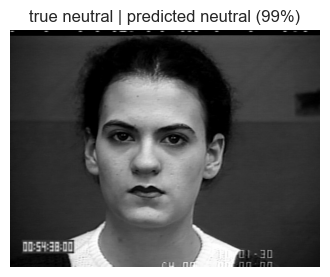

In [40]:
def predict_image(path, max_faces=5):
    img = read_bgr(path)
    if img is None:
        raise ValueError(f"cannot read {path}")
    if USE_FACE_CROP and min(img.shape[:2]) >= ASSUME_CROP_BELOW:
        boxes = FaceCropper(DETECTOR_PATH, FACE_MARGIN).detect(img)[:max_faces]
        faces = [square_crop(img, b, FACE_MARGIN) for b in boxes] or [(center_square(img), None)]
    else:
        faces = [(center_square(img), None)]
    crops = [c if max(c.shape[:2]) <= CROP_SIZE else cv2.resize(c, (CROP_SIZE, CROP_SIZE), interpolation=cv2.INTER_AREA)
             for c, _ in faces]
    p = sess.run(None, {"images": np.stack([onnx_prep(c) for c in crops])})[0]
    return [{"box": box, "label": CLASS_NAMES[int(q.argmax())], "confidence": float(q.max()),
             "probabilities": dict(zip(CLASS_NAMES, np.round(q, 4).tolist()))} for (_, box), q in zip(faces, p)]

if EXPORT_ONNX:
    sample = df[df["split"] == "test"].sample(1, random_state=1).iloc[0]
    res = predict_image(sample["path"])
    print("File:", sample["path"], "| true label:", sample["label"])
    for r in res:
        print(r)
    plt.figure(figsize=(4, 4)); plt.imshow(cv2.cvtColor(read_bgr(sample["path"]), cv2.COLOR_BGR2RGB)); plt.axis("off")
    plt.title(f"true {sample['label']} | predicted {res[0]['label']} ({res[0]['confidence']:.0%})"); plt.show()

## 12. Comparison with the other models

Reads `metrics.json` of every model in `last_codes/outputs/` that has finished so far. All were trained and tested on
the identical split, so the numbers are directly comparable. Re-run this cell after the other notebooks finish.

In [41]:
rows = []
for f in sorted(BASE_OUT.glob("*/metrics.json")):
    m = json.load(open(f))
    rows.append({"model": m["model"], "params (M)": m.get("parameters_millions"), "weights (MB)": m.get("weights_mb"),
                 "test acc": m["accuracy"]["test"], "test macro-F1": m["macro_f1"]["test"], "val acc": m["accuracy"]["val"],
                 "test 95% CI": f"{m['test_ci95'][0]:.3f}-{m['test_ci95'][1]:.3f}", "TTA": m["tta"],
                 "best epoch": m["best_epoch"], "train min": m.get("train_minutes"), "ms/image": m.get("inference_ms_per_image"),
                 **{f"{c} acc": m["per_class_accuracy"]["test"][c] for c in CLASS_NAMES}})
comp = pd.DataFrame(rows).sort_values("test acc", ascending=False).reset_index(drop=True)
comp.to_csv(BASE_OUT / "model_comparison.csv", index=False)
pct = ["test acc", "test macro-F1", "val acc"] + [f"{c} acc" for c in CLASS_NAMES]
display(comp.style.format({**{k: "{:.2%}" for k in pct if k != "test macro-F1"}, "test macro-F1": "{:.4f}"}, na_rep="-")
        .highlight_max(subset=pct, color="#cfe2ff"))
print("Saved", BASE_OUT / "model_comparison.csv")

,model,params (M),weights (MB),test acc,test macro-F1,val acc,test 95% CI,TTA,best epoch,train min,ms/image,angry acc,fear acc,happy acc,neutral acc,sad acc,surprise acc
0,yolov8m,15.780000,31.700000,90.56%,0.9013,91.09%,0.895-0.916,True,29,10.000000,5.650000,88.69%,87.38%,95.63%,89.89%,89.04%,89.63%
1,yolo11l,12.840000,25.900000,89.97%,0.8898,90.31%,0.889-0.910,True,47,20.800000,8.900000,87.30%,78.48%,96.17%,90.53%,90.22%,89.44%
2,yolo11m,10.360000,20.900000,89.88%,0.8881,90.71%,0.888-0.909,True,46,16.300000,8.840000,89.11%,77.15%,95.77%,89.09%,92.41%,87.50%
3,yolo11s,5.450000,11.000000,89.47%,0.8839,90.74%,0.884-0.906,True,55,12.100000,8.270000,87.30%,77.15%,95.08%,89.73%,91.40%,88.15%


Saved D:\Shitol\last_codes\outputs\model_comparison.csv


## Output files (`last_codes/outputs/yolov8m/`)

| File | Content |
|---|---|
| `split.csv` | every image with its split (identical for all four models) |
| `runs/yolov8m_70_15_15/weights/best.pt` | trained PyTorch weights (best validation epoch) |
| `training_curves.png`, `crop_preview.png` | training curves, example face crops |
| `metrics.json` | accuracy, macro-F1 and **per-class accuracy** for every split, test 95 % CI, speed, size |
| `confusion_matrices.png`, `per_class_accuracy.png` | confusion matrices, per-class accuracy chart |
| `predictions_all_splits.csv` | prediction, confidence and class probabilities for every image |
| `no_face_detected.csv` | images where YuNet found no face (centre square used) |
| `yolov8m_face_expression.onnx`, `deployment_metadata.json` | model for the web application |

`last_codes/outputs/model_comparison.csv` – all finished models side by side (section 12).